# Базовый кейс

Выполнил: Тюрин Данил

### Подготоваливаем окружение

In [3]:
from pathlib import Path
import importlib.util
import subprocess
import sys
import warnings

# Доустанавливаем недостающие пакеты (нужно только при первом запуске)
_required = {"numpy": "numpy", "pandas": "pandas", "matplotlib": "matplotlib",
             "seaborn": "seaborn", "plotly": "plotly", "duckdb": "duckdb"}
_missing = [pkg for mod, pkg in _required.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print("Устанавливаю пакеты:", ", ".join(_missing))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *_missing])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from IPython.display import display
import duckdb

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 4)
plt.rcParams["axes.titlesize"] = 12

# Ищем папку data/ с CSV: рядом с ноутбуком, выше по дереву или в подпапке
# (например, если архив распакован в /content в Google Colab)
def find_data_dir(marker: str = "incident_events.csv") -> Path:
    here = Path.cwd().resolve()
    for base in [here, *here.parents]:
        if (base / "data" / marker).exists():
            return base / "data"
    for p in here.glob("**/data/" + marker):
        return p.parent
    raise FileNotFoundError(
        f"Не найдена папка data/ с файлом {marker}. "
        "Откройте ноутбук из распакованной папки adhoc_lecture_handout/."
    )

DATA = find_data_dir()
print("Данные:", DATA)

# Регистрируем CSV как таблицы, чтобы обращаться к ним из SQL
con = duckdb.connect()

def register_csv(name: str, filename: str) -> pd.DataFrame:
    path = DATA / filename
    df = pd.read_csv(path)
    # year/month/day должны остаться строками с ведущими нулями ('07'),
    # иначе фильтр вида day BETWEEN '01' AND '28' сравнит строки неправильно
    for col in ("year", "month", "day"):
        if col in df.columns:
            if col == "year":
                df[col] = df[col].astype("Int64").astype(str)
            else:
                df[col] = df[col].astype("Int64").map(lambda x: f"{int(x):02d}" if pd.notna(x) else None)
    con.register(name, df)
    print(f"{name:28s} {len(df):>8,} строк  <- {filename}")
    return df

impressions = register_csv("impressions", "impressions.csv")
clicks = register_csv("clicks", "clicks.csv")
responses = register_csv("responses", "responses.csv")
product_daily = register_csv("product_daily", "product_daily.csv")
employer_spend = register_csv("employer_spend", "employer_spend.csv")
experiment_clients = register_csv("experiment_clients", "experiment_clients.csv")
incident_events = register_csv("incident_events", "incident_events.csv")

def sql(query: str) -> pd.DataFrame:
    # Выполнить SQL-запрос (в стиле Trino) к синтетическим таблицам
    return con.execute(query).df()

print("\nГотово. Для запросов используйте функцию sql('''...''').")


Данные: /Users/tabletka_812/PycharmProjects/pet_project_a/ad-hoc/adhoc_lecture_handout 2/data
impressions                    80,000 строк  <- impressions.csv
clicks                          3,837 строк  <- clicks.csv
responses                         421 строк  <- responses.csv
product_daily                     252 строк  <- product_daily.csv
employer_spend                  2,400 строк  <- employer_spend.csv
experiment_clients             12,573 строк  <- experiment_clients.csv
incident_events                25,500 строк  <- incident_events.csv

Готово. Для запросов используйте функцию sql('''...''').


### Контекст
> 20 июля на Android кликабельность `top_search` резко выше обычной. Что это: ошибка трекинга, и тогда чиним логирование, или реальный эффект, и тогда решаем, менять ли формат показа на Android?

## ТЗ по семи вопросам до SQL: решение сформулировано до анализа + Выбранная ступень глубины (прикидка, разбор или глубокий разбор) и пара предложений, почему: цена ошибки и можно ли откатить без следа

- Заказчик: Иван, Senior-продакт
- Проблема: 20 июля на android кликабельность top_search резко выросла. Непонятно, это ошибка трекинга или пользователи реально стали больше кликать
- Цель: понять, баг это или реальный эффект, чтобы решить: чинить логирование или думать про изменение формата показа на android
- Гипотеза: всплеск - это ошибка логирования кликов на android. То есть кликов стало больше, а откликов от этого не прибавилось

  Если эффект реальный, то вместе с кликами должны вырасти и отклики
- Метрика: кликабельность = клики / показы (top_search, по дням, по платформам). Дополнительно смотрю конверсию клик → отклик и показ → отклик
- Период: тест: 20 июля; контроль: остальные дни 1–28 июля на android + другие платформы за 20 июля
- Сегменты: платформа, продукт (top_search / top_boost), сегмент работодателя (SMB / Large / Premium)
- Критерий успеха: Считаем ошибкой трекинга, если кликабельность 20 июля выходит за доверительный интервал обычных дней, а показ → отклик в норме. Если вырос и показ → отклик - реальный эффект.
- Решение по результату: если баг, то чиним логирование на android и убираем 20 июля из расчетов. Если реальный эффект, то разбираемся, что поменялось, и проверяем новый формат через эксперимент, допустим A/B
- Дедлайн: до 19 ноября
- Глубина: разбор
- Почему: если ошибемся, команда потратит время на ненужное изменение формата или в отчетах какое-то время будут неверные цифры. Но все откатывается обратно без следа: формат можно вернуть, деньги клиентов и их время не затронуты. Цена ошибки средняя

## Раздел про качество данных: что проверили и что нашли

### Функции для ad-hoc

In [5]:
from typing import Iterable, Optional, Sequence, Tuple


def wilson_ci(successes: float, n: float, z: float = 1.96) -> Tuple[float, float]:
    # Доверительный интервал Уилсона для доли. Устойчивее нормального приближения
    # на малых выборках и у краёв (доля близка к 0 или 1).
    if n <= 0:
        return (np.nan, np.nan)
    p = successes / n
    denom = 1 + z**2 / n
    center = (p + z**2 / (2 * n)) / denom
    margin = z * np.sqrt((p * (1 - p) + z**2 / (4 * n)) / n) / denom
    return (max(0.0, center - margin), min(1.0, center + margin))


def proportion_table(
    df: pd.DataFrame,
    group_cols: Sequence[str],
    success_col: str,
    n_col: str,
    rate_name: str = "rate",
) -> pd.DataFrame:
    # Считает долю по группам и добавляет доверительный интервал Уилсона.
    g = df.groupby(list(group_cols), as_index=False).agg(
        successes=(success_col, "sum"),
        n=(n_col, "sum"),
    )
    g[rate_name] = g["successes"] / g["n"]
    cis = g.apply(lambda r: wilson_ci(r["successes"], r["n"]), axis=1)
    g["ci_low"] = cis.map(lambda x: x[0])
    g["ci_high"] = cis.map(lambda x: x[1])
    return g


def period_flag(dates: pd.Series, cutoff: str, before="before", after="after") -> pd.Series:
    # Размечает даты на период до и после точки cutoff.
    d = pd.to_datetime(dates)
    return np.where(d < pd.Timestamp(cutoff), before, after)


def summarize_dq(df: pd.DataFrame, key_cols: Optional[Iterable[str]] = None) -> pd.DataFrame:
    # Быстрая сводка по качеству данных: размер, дубли, пропуски по колонкам,
    # при указании ключа считаем также дубли по ключу.
    rows = []
    rows.append({"проверка": "строк всего", "значение": len(df)})
    rows.append({"проверка": "полных дублей строк", "значение": int(df.duplicated().sum())})
    for c in df.columns:
        rows.append({"проверка": f"пропуски: {c}", "значение": int(df[c].isna().sum())})
    if key_cols:
        key_cols = list(key_cols)
        rows.append({
            "проверка": f"дубли по ключу: {'+'.join(key_cols)}",
            "значение": int(df.duplicated(key_cols).sum()),
        })
    return pd.DataFrame(rows)


def one_pager(
    decision: str,
    context: str,
    what_done: str,
    result: str,
    limits: str,
    action: str,
) -> str:
    # Собирает итоговую справку с выводом наверху.
    parts = [
        "=" * 60,
        "ИТОГОВАЯ СПРАВКА",
        "=" * 60,
        "",
        "Решение:",
        decision,
        "",
        "Контекст:",
        context,
        "",
        "Что сделали:",
        what_done,
        "",
        "Результат:",
        result,
        "",
        "Ограничения:",
        limits,
        "",
        "Рекомендованное действие:",
        action,
        "=" * 60,
    ]
    return "\n".join(parts)


print("Функции загружены: wilson_ci, proportion_table, period_flag, summarize_dq, one_pager")


Функции загружены: wilson_ci, proportion_table, period_flag, summarize_dq, one_pager


### Непосредственно сама проверка данных

In [6]:
# проверяю дубли и пропуски в таблицах
summarize_dq(impressions, key_cols=["impression_id"])

,проверка,значение
0,строк всего,80000
1,полных дублей строк,0
2,пропуски: impression_id,0
3,пропуски: event_date,0
4,пропуски: platform,0
5,пропуски: segment,0
6,пропуски: product,0
7,пропуски: vacancy_id,0
8,пропуски: employer_id,0
9,пропуски: hhuid,0


In [7]:
summarize_dq(clicks, key_cols=["click_id"])

,проверка,значение
0,строк всего,3837
1,полных дублей строк,0
2,пропуски: click_id,0
3,пропуски: impression_id,0
4,пропуски: event_date,0
5,пропуски: platform,0
6,пропуски: segment,0
7,пропуски: product,0
8,пропуски: vacancy_id,0
9,пропуски: employer_id,0


In [8]:
summarize_dq(responses, key_cols=["response_id"])

,проверка,значение
0,строк всего,421
1,полных дублей строк,0
2,пропуски: response_id,0
3,пропуски: click_id,0
4,пропуски: impression_id,0
5,пропуски: event_date,0
6,пропуски: platform,0
7,пропуски: segment,0
8,пропуски: product,0
9,пропуски: vacancy_id,0


In [11]:
# может ли быть несколько кликов на один показ
clicks["impression_id"].value_counts().max()

np.int64(1)

In [12]:
# клики без показа и отклики без клика
print(len(clicks[~clicks["impression_id"].isin(impressions["impression_id"])]))
print(len(responses[~responses["click_id"].isin(clicks["click_id"])]))

0
0


In [13]:
# проверяю, что у клика и показа совпадает дата и платформа
m = clicks.merge(impressions, on="impression_id", suffixes=("_click", "_imp"))
print((m["event_date_click"] != m["event_date_imp"]).sum())
print((m["platform_click"] != m["platform_imp"]).sum())

0
0


In [14]:
# какие даты и платформы есть в данных
print(impressions["event_date"].min(), impressions["event_date"].max())
print(impressions["platform"].unique())

2026-07-01 2026-07-28
<StringArray>
['IOS', 'MOBILE_WEB', 'ANDROID', 'DESKTOP_WEB']
Length: 4, dtype: str


In [17]:
# почему показы top_search упали с 15 июля
android_all = impressions[impressions["platform"] == "ANDROID"]
by_product = android_all.groupby(["event_date", "product"]).size().unstack()
by_product["всего"] = by_product.sum(axis=1)
by_product.loc["2026-07-12":"2026-07-18"]

product,top_boost,top_search,всего
event_date,,,
2026-07-12,NaN,656.0,656.0
2026-07-13,NaN,636.0,636.0
2026-07-14,NaN,629.0,629.0
2026-07-15,216.0,377.0,593.0
2026-07-16,240.0,396.0,636.0
2026-07-17,231.0,399.0,630.0
2026-07-18,246.0,371.0,617.0


### Качество данных

Проверил дубли, пропуски во всех таблицах, даты, а также связи между ними и платформы

Что нашел: Ошибок в данных обнаружено не было. Увидел, что количество показов после 15 июля резко сократилось.

Что это значит: количество показов top_search после 15 июля упало, потому что в этот день запустили top_boost. Это видно в таблице выше: до 15 июля top_boost нет, а после сумма двух продуктов на android та же, примерно 600 в день. Это не ошибка данных, но из-за этого сравниваю 20 июля только с днями 15–28 июля.

Что это значит: показов top_search после 15 июля стало меньше, потому что запустили top_boost и часть показов ушла туда. По таблице выше видно, что до 15 июля top_boost нет, а после сумма двух продуктов на android примерно та же (~600 в день). То есть это не ошибка в данных. Но из-за этого 20 июля сравниваю только с 15–28 июля

In [25]:
# беру данные только с 15 июля (после запуска top_boost)
imp = impressions[impressions["event_date"] >= "2026-07-15"].copy()
clk = clicks[clicks["event_date"] >= "2026-07-15"].copy()
rsp = responses[responses["event_date"] >= "2026-07-15"].copy()

# помечаю 20 июля отдельно от остальных дней
imp["period"] = np.where(imp["event_date"] == "2026-07-20", "20 июля", "обычные дни")
clk["period"] = np.where(clk["event_date"] == "2026-07-20", "20 июля", "обычные дни")
rsp["period"] = np.where(rsp["event_date"] == "2026-07-20", "20 июля", "обычные дни")

# считаю показы, клики и отклики по продукту, платформе и периоду
cols = ["product", "platform", "period"]
res = imp.groupby(cols).size().reset_index(name="impressions")
res = res.merge(clk.groupby(cols).size().reset_index(name="clicks"), on=cols, how="left")
res = res.merge(rsp.groupby(cols).size().reset_index(name="responses"), on=cols, how="left")
res = res.fillna(0)

# метрики
res["ctr"] = res["clicks"] / res["impressions"]
res["imp_to_resp"] = res["responses"] / res["impressions"]
res["click_to_resp"] = res["responses"] / res["clicks"]


ctr_low, ctr_high, resp_low, resp_high = [], [], [], []
for i, row in res.iterrows():
    low, high = wilson_ci(row["clicks"], row["impressions"])
    ctr_low.append(low)
    ctr_high.append(high)
    low, high = wilson_ci(row["responses"], row["impressions"])
    resp_low.append(low)
    resp_high.append(high)
res["ctr_low"] = ctr_low
res["ctr_high"] = ctr_high
res["resp_low"] = resp_low
res["resp_high"] = resp_high

res.round(4)

,product,platform,period,impressions,clicks,responses,ctr,imp_to_resp,click_to_resp,ctr_low,ctr_high,resp_low,resp_high
0,top_boost,ANDROID,20 июля,252,29,4,0.1151,0.0159,0.1379,0.0813,0.1604,0.0062,0.0401
1,top_boost,ANDROID,обычные дни,3073,136,28,0.0443,0.0091,0.2059,0.0375,0.0521,0.0063,0.0131
2,top_boost,DESKTOP_WEB,20 июля,429,34,1,0.0793,0.0023,0.0294,0.0573,0.1087,0.0004,0.0131
3,top_boost,DESKTOP_WEB,обычные дни,5425,390,20,0.0719,0.0037,0.0513,0.0653,0.0791,0.0024,0.0057
4,top_boost,IOS,20 июля,186,8,2,0.0430,0.0108,0.2500,0.0220,0.0826,0.0030,0.0384
5,top_boost,IOS,обычные дни,2579,109,25,0.0423,0.0097,0.2294,0.0352,0.0507,0.0066,0.0143
6,top_boost,MOBILE_WEB,20 июля,246,14,1,0.0569,0.0041,0.0714,0.0342,0.0932,0.0007,0.0227
7,top_boost,MOBILE_WEB,обычные дни,3109,205,20,0.0659,0.0064,0.0976,0.0577,0.0752,0.0042,0.0099
8,top_search,ANDROID,20 июля,383,36,4,0.0940,0.0104,0.1111,0.0687,0.1274,0.0041,0.0265
9,top_search,ANDROID,обычные дни,4990,147,22,0.0295,0.0044,0.1497,0.0251,0.0345,0.0029,0.0067


Что получилось: на android 20 июля кликабельность top_search 9,4%, а в обычные дни 2,95%, интервалы не пересекаются. У top_boost на android, по сути то же самое: 11,5% против 4,4%. А на iOS все как обычно. Получается, что проблема в android, а не в продукте. При этом, я заметил, что конверсия из показа в отклики почти не изменился, также как конверсия из кликов в отклик. Получается лишние клики в отклики не превратились, это все больше похоже на ошибку трекинга

### Графики

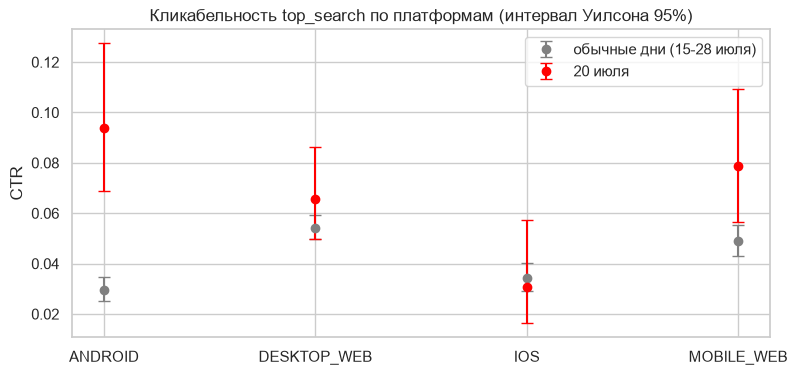

In [21]:
# График, который показывает ctr top_search по платформам + сравнение обычных дней с 20 июля
ts = res[res["product"] == "top_search"]
normal = ts[ts["period"] == "обычные дни"]
day20 = ts[ts["period"] == "20 июля"]

plt.figure(figsize=(9, 4))
plt.errorbar(normal["platform"], normal["ctr"], yerr=[normal["ctr"] - normal["ctr_low"], normal["ctr_high"] - normal["ctr"]],
             fmt="o", capsize=4, color="grey", label="обычные дни (15-28 июля)")
plt.errorbar(day20["platform"], day20["ctr"], yerr=[day20["ctr"] - day20["ctr_low"], day20["ctr_high"] - day20["ctr"]],fmt="o", capsize=4, color="red", label="20 июля")
plt.title("Кликабельность top_search по платформам (интервал Уилсона 95%)")
plt.ylabel("CTR")
plt.legend()
plt.show()

Видно, что красная точка андроид далеко выше серой, интервалы не пересекаются. На остальных платформах интервалы пересекаются

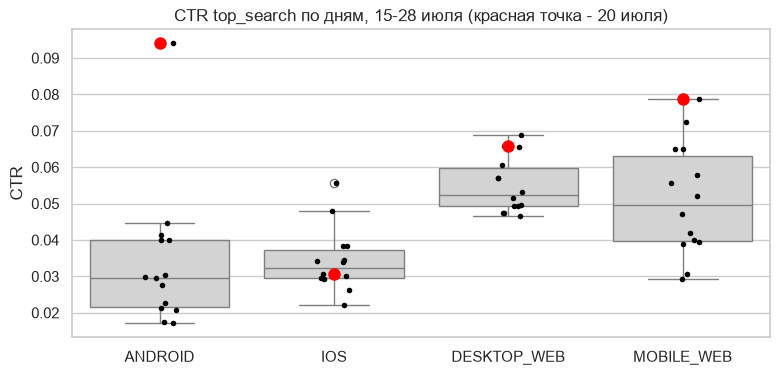

In [23]:
# График, который показывает распределение ctr по дням
d_imp = imp[imp["product"] == "top_search"].groupby(["event_date", "platform"]).size().reset_index(name="impressions")
d_clk = clk[clk["product"] == "top_search"].groupby(["event_date", "platform"]).size().reset_index(name="clicks")
by_day = d_imp.merge(d_clk, on=["event_date", "platform"], how="left").fillna(0)
by_day["ctr"] = by_day["clicks"] / by_day["impressions"]

order = ["ANDROID", "IOS", "DESKTOP_WEB", "MOBILE_WEB"]

plt.figure(figsize=(9, 4))
sns.boxplot(data=by_day, x="platform", y="ctr", order=order, color="lightgrey")
sns.stripplot(data=by_day, x="platform", y="ctr", order=order, color="black", size=4)
sns.stripplot(data=by_day[by_day["event_date"] == "2026-07-20"], x="platform", y="ctr", order=order, color="red", size=9)
plt.title("CTR top_search по дням, 15-28 июля (красная точка - 20 июля)")
plt.ylabel("CTR")
plt.xlabel("")
plt.show()

20 июля на андроид сильно выше всех остальных дней, на других платформах точка внутри обычного разброса

In [24]:
# почему показы top_search упали с 15 июля - смотрю оба продукта на android
android_all = impressions[impressions["platform"] == "ANDROID"]
by_product = android_all.groupby(["event_date", "product"]).size().unstack()
by_product["всего"] = by_product.sum(axis=1)
by_product.loc["2026-07-12":"2026-07-18"]

product,top_boost,top_search,всего
event_date,,,
2026-07-12,NaN,656.0,656.0
2026-07-13,NaN,636.0,636.0
2026-07-14,NaN,629.0,629.0
2026-07-15,216.0,377.0,593.0
2026-07-16,240.0,396.0,636.0
2026-07-17,231.0,399.0,630.0
2026-07-18,246.0,371.0,617.0


## Итоговая справка

Вывод: скачок кликабельности top_search на android 20 июля - это скорее всего ошибка трекинга. Формат показа на android не меняем, отдаем разработчикам проверить логирование кликов, а 20 июля убираем из расчетов

Что нашел:
- кликабельность на android 20 июля 9,4%, а обычно 2,95%
- в тот же день так же вырос top_boost на android, а на iOS все нормально, значит проблема в android-приложении
- откликов вроде тоже стало чуть больше, но их слишком мало, интервалы пересекаются, так что значимого роста нет. А клик → отклик вообще ниже обычного: 11% против 15%. То есть лишние клики в отклики не дошли
- показы 20 июля обычные, дублей и пропусков в данных нет

Ограничения: откликов за день мало 4, логов приложения нет, поэтому точную причину не нашел

Что дальше: android-разработчики проверяют логирование кликов за 20 июля, если найдут баг, то чинят, и пересчитываем метрики за этот день

## Ограничения
- Откликов 20 июля на android всего 4, поэтому интервал для показ - отклик широкий и точно сказать, что отклики не выросли, нельзя
- Нет логов приложения и информации о релизах, поэтому что именно сломалось в трекинге - не знаю
- На mobile_web 20 июля кликабельность тоже выше обычной 7,9% против 4,9%, интервалы почти не пересекаются, но по дням это все еще в пределах разброса. Возможно 20 июля был еще какой-то общий фактор, отдельно не разбирал
- В ТЗ планировал разрез по сегментам работодателя (SMB / Large / Premium), но не стал делать: кликов за 20 июля на android всего 36, по сегментам получится по несколько штук и выводов из этого не сделать
- Кликабельность считал как обычную долю с интервалом Уилсона, это ок, потому что почти каждый пользователь видел один показ. В реальных данных это была бы ratio-метрика и интервал надо было бы считать по-другому (дельта-метод или бутстрэп)
- Обычных дней для сравнения всего 13 (15–28 июля без 20-го)